# Do algorithm bans work the same in Llama? — the FRLP ban-substitution screen (demo)

*"Implement a path search algorithm"*: does an LLM always write BFS? And when the prompt **bans** BFS, does it
*substitute* one specific runner-up, or does it just drop BFS and fall back on a generic typicality ladder? This
artifact answers these questions for **meta-llama/Llama-3.1-8B-Instruct** (bf16, default chat template). It is the
second-model-family replication of the screen, run on two path-search tasks: **T1** grid path (6 catalogue
algorithms) and **T2** weighted shortest path.

**What the experiment did**

* **Sampling.** 1,780 seeded vLLM generations: baseline prompts, *"do not use X"* bans (5 templates W1–W5),
  *mention* twins that name X without banning it, *list-all* prompts, two-step bans, forced *"Implement X"* prompts
  and free-form *"What is the standard alternative to X?"* questions. A canonical labeller (runtime probes and AST
  rules, with an LLM judge on disagreement) gives every program its mechanism label (BFS, DFS, A\*, ...).
* **FRLP, the forced-ratio latent probability (the method).** For each algorithm *j*, the model's own programs
  written under forced "Implement *j*" prompts are name-scrubbed. A Hugging Face forward pass then scores each
  program under every experimental prompt *c*, and importance weighting turns the scores into an estimate of
  log P(model writes *j* | *c*):

  $$L_j(c) = \log \frac{1}{M_j}\sum_{m=1}^{M_j} \exp\big[\,\ell(p_{jm}\mid c) - \ell(p_{jm}\mid F_j)\big]$$

  Here $\ell(p\mid c)$ is the summed token log-probability of program $p$ after prompt $c$, and $F_j$ is the mixture
  of forced prompts for $j$ (the proposal).
* **Per-sample predictors** (what `method.py outputs` writes). For each sampled program, FRLP top-1 among the
  non-banned algorithms is compared with three baselines: the *latent ladder* (mean baseline FRLP), the *sampled
  ladder* (baseline sampling frequency) and *association* (Llama's free-form "standard alternative to X" answer).

**What this notebook runs.** `method.py` is a stage orchestrator. Generation and scoring need a 24 GB GPU and the
gated Llama weights (about 0.64 GPU-hours), and labelling calls an OpenRouter judge, so those stages are shown but not
run. The notebook runs the CPU stage **`outputs`** end to end on a curated subset. `mini_demo_data.json` holds 100 T1
sampled programs and the raw HF scores of the 156 self-written T1 programs under 135 prompts. The notebook:

1. rebuilds every FRLP cell $L_j(c)$ from the raw per-program scores,
2. predicts each sampled program with FRLP top-1 and the three baselines, and scores the predictors,
3. assembles `method_out.json` and checks its predictions against the ones the full run stored.

**Headline results of the full run** (descriptive, because there are two tasks and one model):

* T1 baseline: BFS 77 and DFS 20 of 100, so T1 is not collapsed. Banning BFS gives DFS 63/100.
* T2 is collapsed on Dijkstra (92/100).
* The FRLP validity gate **fails**. FRLP implies BFS 0.43 against a sampled 0.77, and the median cell ESS is 2.5.
* Per-sample top-1 accuracy over 743 samples: the empirical sampled ladder (0.70) beats FRLP (0.59). On single
  bans the two tie (0.67 vs 0.67).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py and its helper modules log with it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

# Not needed for this demo: vllm, torch and transformers (GPU generation and HF scoring stages), rapidfuzz (code
# proximity analysis) and pyarrow (the parquet score files, which mini_demo_data.json replaces with JSON).

In [2]:
from __future__ import annotations

# ---- method.py imports (unchanged)
import argparse
import collections
import json
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- imports of the helper modules inlined below (src/analysis_c1.py, src/run_analysis.py, canon/common.py)
import hashlib
import itertools
import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ---- notebook additions
from types import SimpleNamespace  # stands in for the src.analysis_c1 / src.run_analysis / canon.common modules

import matplotlib.pyplot as plt

# method.py did:  ROOT = Path(__file__).resolve().parent;  sys.path.insert(0, str(ROOT))
#                 from src.ws import C, DATA, FRLP_DIR, RESULTS, read_jsonl, setup_logging, write_json
# There is no experiment folder in the notebook: the "workspace bridge" cell below re-creates these names on top of
# the files shipped in mini_demo_data.json.

PY = sys.executable

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-10/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print(f'{len(data["examples"])} curated examples of {data["metadata"]["dataset"]}, '
      f'{len(data["files"])} experiment-folder files')

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Do algorithm bans work the same in Llama? -- mini demo data
100 curated examples of T1_grid_path__llama31_sampled, 30 experiment-folder files


## Configuration

Every tunable parameter of the demo is set here. The `outputs` stage itself takes well under a second on a CPU, so
the notebook's run time is mostly package installation.

In [5]:
# How many curated T1 sampled programs go through method.py's `outputs` stage. Tested at 10 -> 50 -> 100 (about 0.03 s
# of compute each); mini_demo_data.json holds 100, stratified over the 7 sampled T1 events, so 100 runs all of them.
N_EXAMPLES = 100
# Original (full run): every labelled row, i.e. 450 T1 + 450 T2 sampled programs. That needs the full
# data/labelled.jsonl and score matrices, which the mini data does not ship:
# N_EXAMPLES = 900
# Tasks to process. Original (src/run_analysis.py): TASKS = ("t1", "t2"); the mini data ships T1 only.
TASKS = ("t1",)
# FRLP cell variant used by outputs(). Original: "full" (proposal = mixture of all forced prompts of j).
# The shipped scores also support "body", "gen_proposal", "exp1_5tpl" and "correct_only".
FRLP_VARIANT = "full"
# Where the stage writes. Original: data/samples.jsonl and method_out.json inside the experiment folder.
OUT_DIR = Path("demo_outputs")
OUT_DIR.mkdir(exist_ok=True)

## Workspace bridge (replaces `src/ws.py` and the parts of `canon/common.py` in use)

In the experiment folder, `src/ws.py` defined the layout (`data/`, `frlp/`, `results/`) and imported the canonical
task suite `canon/common.py` as `C`. This cell re-creates the same names, with two changes:

* Every file is served from the `files` table of `mini_demo_data.json`, keyed by its original relative path
  (`results/selections.json`, `data/forced_set.jsonl`, ...). `data/labelled.jsonl` holds the first `N_EXAMPLES` curated
  examples.
* Every file the code writes goes to `OUT_DIR`.

The FRLP score files `frlp/parts/t1/*.parquet` ship as one compact table with columns program index, prompt index,
`l_full`, `l_body` and `n_tokens`. `score_parts()` rebuilds the DataFrame that `pd.read_parquet` returned. Apart from
these reads and writes, which are marked `[notebook]`, the code below is unchanged.

In [6]:
# ---- canon/common.py: the catalogue and dataset names (copied)
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* or greedy best-first search",
        "dijkstra": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in ("t1", "t2")}

# ---- src/ws.py: the experiment-folder layout, now keys into the shipped file table
ROOT = Path(".")
DATA = ROOT / "data"
FRLP_DIR = ROOT / "frlp"
RESULTS = ROOT / "results"
MODEL_TAG = "llama-3.1-8b-instruct"

FILES: dict[str, Any] = dict(data["files"])                   # original relative path -> file content
FILES["data/labelled.jsonl"] = data["examples"][:N_EXAMPLES]  # the labelled sampled programs (curated subset)


def _file(p: Path) -> Any:
    """Content of experiment-folder file `p`, served from mini_demo_data.json (None if the demo does not ship it)."""
    return FILES.get(Path(p).as_posix())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return list(_file(p) or [])  # like canon's read_jsonl, [] for a missing file


def write_jsonl(p: Path, rows) -> None:
    with (OUT_DIR / Path(p).name).open("w") as fh:  # every write goes to OUT_DIR
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    (OUT_DIR / Path(p).name).write_text(json.dumps(obj, indent=indent, ensure_ascii=False))


def sha256_file(p: Path) -> str:
    return hashlib.sha256(_file(p).encode("utf-8")).hexdigest()  # such files are shipped as their raw text


def score_parts(p: Path) -> pd.DataFrame:
    """frlp/parts/<task>/*.parquet concatenated (columns program_id, cond, l_full, l_body, n_tokens), rebuilt from the
    compact table in mini_demo_data.json."""
    t = _file(p)
    df = pd.DataFrame(t["rows"], columns=t["columns"])
    return pd.DataFrame({"program_id": np.asarray(t["program_ids"], dtype=object)[df["program"].to_numpy()],
                         "cond": np.asarray(t["conds"], dtype=object)[df["cond"].to_numpy()],
                         "l_full": df["l_full"].astype(float), "l_body": df["l_body"].astype(float),
                         "n_tokens": df["n_tokens"].astype(int)})


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # src/ws.py also added a file sink, logs/<name>.log (rotation 30 MB)


C = SimpleNamespace(TASK_DATASET_NAME=TASK_DATASET_NAME, CATALOGUE=CATALOGUE, MODES=MODES,
                    read_jsonl=read_jsonl, write_jsonl=write_jsonl, sha256_file=sha256_file)
setup_logging("method")
print(len(FILES), "files:", ", ".join(sorted(FILES)))

31 files: commitments.log, data/dependency_inventory.json, data/forced_set.jsonl, data/free_answers.jsonl, data/labelled.jsonl, frlp/parts/t1, logs/timing.jsonl, results/bootstrap_diagnostics.json, results/c1.json, results/collapse.json, results/coverage.json, results/deviations.json, results/events.json, results/forced_set_summary.json, results/frlp_gate.json, results/frozen_config.json, results/independent_rederivation.json, results/independent_rederivation_headlines.json, results/labeller_recheck.json, results/llama_label_audit.json, results/model_record.json, results/openrouter_cost.json, results/scrub_stress.json, results/selections.json, results/sensitivities.json, results/t3_token_check.json, results/test_analysis_c1.json, results/tests_frlp_sanity.json, results/tests_prompts.json, results/tests_scoring_B.json, results/tests_scoring_D.json


## The FRLP estimator (from `src/analysis_c1.py`)

`method.py outputs` imports `src.analysis_c1` as `A`. The part that turns raw scores into FRLP cells is copied
unchanged:

* `TaskData` holds one task's two score matrices, each programs × prompts: `lf` scores the whole response and `lb`
  the code body. It also holds the program table (algorithm *j*, half, pass flag, generating prompt).
* `proposal()` gives each program's log-proposal $\log q(p)=\ell(p\mid F_j)$, a log-mean-exp over the forced prompts
  of its own algorithm.
* `importance()` returns the log importance ratios $D = \ell(p\mid c) - \log q(p)$.
* `make_cells()` log-mean-exps those ratios per algorithm into $L_j(c)$, over all programs and per random half. It
  also returns the effective sample size $\mathrm{ESS} = (\sum w)^2/\sum w^2$ of the importance weights.

In [7]:
# ---- src/analysis_c1.py (frozen in commitments.log): the FRLP part that method.py's `outputs` stage uses, unchanged
TEMPLATES = (1, 2, 3, 4, 5)
HALVES = (1, 2)
ESS_FLOOR = 5.0


# ================================================================================================ data
@dataclass
class TaskData:
    task: str
    algs: list[str]  # FRLP-measured algorithms (catalogue order)
    d: str
    s_star: str
    prog: pd.DataFrame  # program_id, j, half, passed, generating_cond (row order of the matrices)
    conds: list[str]
    lf: np.ndarray  # [P, C] l_full (NaN = not scored)
    lb: np.ndarray  # [P, C] l_body
    cidx: dict[str, int] = field(default_factory=dict)
    jidx: np.ndarray | None = None  # [P] algorithm index
    hidx: np.ndarray | None = None  # [P] half index 0/1

    def __post_init__(self):
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.jidx = np.array([self.algs.index(j) for j in self.prog["j"]])
        self.hidx = np.array([int(h) - 1 for h in self.prog["half"]])

    def has(self, c: str) -> bool:
        return c in self.cidx


def logmeanexp(a: np.ndarray, axis: int = -1) -> np.ndarray:
    m = np.nanmax(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    with np.errstate(invalid="ignore"):
        e = np.exp(a - m)
    e = np.where(np.isnan(a), 0.0, e)
    n = np.sum(~np.isnan(a), axis=axis, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        out = m + np.log(np.sum(e, axis=axis, keepdims=True) / n)
    return np.where(n > 0, out, np.nan).squeeze(axis)


def proposal(td: TaskData, variant: str = "full") -> np.ndarray:
    """log q(p) = l(p | F_j): mixture over every forced prompt used for j (full / body), the generating paraphrase
    ('gen_proposal'), or exp1's 5 standard templates ('exp1_5tpl')."""
    mat = td.lb if variant == "body" else td.lf
    out = np.full(len(td.prog), np.nan)
    pcols = [i for c, i in td.cidx.items() if c.startswith("forced:") or c.startswith("forced_desc:")]
    for r, (j, gen) in enumerate(zip(td.prog["j"], td.prog["generating_cond"])):
        if variant == "gen_proposal":
            out[r] = mat[r, td.cidx[gen]]
            continue
        if variant == "exp1_5tpl":
            cols = [td.cidx[f"forced:{j}:k{k}"] for k in range(5) if f"forced:{j}:k{k}" in td.cidx]
        else:
            cols = [i for i in pcols if td.conds[i].split(":")[1] == j]
        v = mat[r, cols]
        out[r] = logmeanexp(v[~np.isnan(v)]) if np.any(~np.isnan(v)) else np.nan
    return out


# ================================================================================================ cells
@dataclass
class Cells:
    Lh: np.ndarray  # [J, 2, C]
    La: np.ndarray  # [J, C]
    ESSh: np.ndarray  # [J, 2, C]
    ESSa: np.ndarray  # [J, C]
    Nh: np.ndarray  # [J, 2] programs per half (with multiplicity)


def make_cells(td: TaskData, D: np.ndarray, counts: np.ndarray | None = None, mask: np.ndarray | None = None) -> Cells:
    """D [P, C] = log importance ratios; counts [P] bootstrap multiplicities; mask [P] program subset."""
    P, C = D.shape
    J = len(td.algs)
    w = np.ones(P) if counts is None else counts.astype(float)
    if mask is not None:
        w = w * mask
    Lh = np.full((J, 2, C), np.nan)
    ESSh = np.full((J, 2, C), np.nan)
    La = np.full((J, C), np.nan)
    ESSa = np.full((J, C), np.nan)
    Nh = np.zeros((J, 2))
    for j in range(J):
        sel_j = td.jidx == j
        Dj = D[sel_j]
        wj = w[sel_j]
        hj = td.hidx[sel_j]
        valid = ~np.isnan(Dj)
        with np.errstate(all="ignore"):
            import warnings
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                M = np.nanmax(np.where(valid & (wj[:, None] > 0), Dj, np.nan), axis=0) if np.any(wj > 0) else np.full(C, np.nan)
        M = np.where(np.isfinite(M), M, 0.0)
        E = np.where(valid, np.exp(np.where(valid, Dj, 0.0) - M), 0.0)
        for h in (0, 1):
            sh = (hj == h)
            ww = (wj * sh)[:, None] * valid
            s1 = np.sum(ww * E, axis=0)
            s2 = np.sum(ww * E ** 2, axis=0)
            n = np.sum(ww, axis=0)
            Nh[j, h] = float(np.sum(wj * sh))
            with np.errstate(divide="ignore", invalid="ignore"):
                Lh[j, h] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
                ESSh[j, h] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
        ww = wj[:, None] * valid
        s1 = np.sum(ww * E, axis=0)
        s2 = np.sum(ww * E ** 2, axis=0)
        n = np.sum(ww, axis=0)
        with np.errstate(divide="ignore", invalid="ignore"):
            La[j] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
            ESSa[j] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
    return Cells(Lh=Lh, La=La, ESSh=ESSh, ESSa=ESSa, Nh=Nh)


def importance(td: TaskData, variant: str = "full") -> np.ndarray:
    base = td.lb if variant == "body" else td.lf
    lq = proposal(td, variant if variant in ("body", "gen_proposal", "exp1_5tpl") else "full")
    return base - lq[:, None]

`View` reads the cells by prompt name:

* `a(cond, algs)` is $L_j(c)$, and `h(cond, h, algs)` is the half-specific value.
* `G(X, w, h, algs)` is the gain of the ban of X (template *w*) over its length-matched neutral twin.
* `generic()` and `u()` build the external-ladder profile of the C1 test from nonce, edit and novelty prompts. This
  demo does not ship those prompts, so the two return NaN here.

The C1 decomposition, AIM nulls, FRLP gate and bootstrap in the same module are run by `src/run_analysis.py`, not by
`method.py`. `build_metadata()` below reads their frozen results. `jsonable()` makes the output JSON-safe, and the `A`
namespace at the end stands in for `from src import analysis_c1 as A`.

In [8]:
# ================================================================================================ helpers
def centre(v: np.ndarray) -> np.ndarray:
    return v - np.mean(v)


def unit(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    return v / n if n > 0 else v * np.nan


class View:
    """Accessors over one Cells object with a template draw `tw` (list of 5 template ids)."""

    def __init__(self, td: TaskData, cells: Cells, tw: list[int] | None = None):
        self.td, self.c = td, cells
        self.tw = list(tw) if tw is not None else list(TEMPLATES)
        self.ai = {a: i for i, a in enumerate(td.algs)}

    def h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.Lh[self.ai[a], h - 1, ci] for a in algs])

    def a(self, cond: str, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.La[self.ai[a], ci] for a in algs])

    def ess_h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.ESSh[self.ai[a], h - 1, ci] for a in algs])

    # ---- gains
    def G(self, X: str, w: int, h: int, algs: list[str], ref: str = "neutral") -> np.ndarray:
        ban = self.h(f"ban:{X}:w{w}", h, algs)
        if ref == "neutral":
            return ban - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)
        return ban - self.h(f"mention:{X}:w{w}", h, algs)  # veto row (mention reference)

    def prime(self, X: str, w: int, h: int, algs: list[str]) -> np.ndarray:
        return self.h(f"mention:{X}:w{w}", h, algs) - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)

    # ---- generic profiles over all algorithms
    def generic(self, half: int | None = None) -> dict[str, np.ndarray]:
        algs = self.td.algs
        out: dict[str, np.ndarray] = {}
        hs = HALVES if half is None else (half,)
        out["nonce"] = np.nanmean([self.h(f"nonce:w{w}", h, algs) - self.h(f"nonce_neutral:w{w}:h{h}", h, algs)
                                   for w in self.tw for h in hs], axis=0)
        get = (lambda c: self.a(c, algs)) if half is None else (lambda c: self.h(c, half, algs))
        for k in range(1, 7):
            if self.td.has(f"edit:k{k}"):
                out[f"edit{k}"] = get(f"edit:k{k}") - get("baseline_empty")
        out["novelty"] = get("novelty") - np.nanmean([get(f"baseline:s{s}") for s in range(5)], axis=0)
        return out

    def u(self, half: int | None = None, raw_mean: bool = False) -> np.ndarray:
        g = self.generic(half)
        edits = [g[k] for k in g if k.startswith("edit")]
        if raw_mean:
            return np.mean([g["nonce"]] + edits + [g["novelty"]], axis=0)
        types = [g["nonce"], np.mean(edits, axis=0) if edits else np.full(len(self.td.algs), np.nan), g["novelty"]]
        types = [unit(centre(t)) for t in types if not np.any(np.isnan(t))]
        if not types:  # degenerate bootstrap draw (a half with no programs): undefined profile
            return np.full(len(self.td.algs), np.nan)
        return np.mean(types, axis=0)


def jsonable(o: Any) -> Any:
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return [jsonable(v) for v in o.tolist()]
    if isinstance(o, (np.floating, float)):
        return None if (isinstance(o, float) or isinstance(o, np.floating)) and not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o


# stands in for `from src import analysis_c1 as A`
A = SimpleNamespace(TEMPLATES=TEMPLATES, HALVES=HALVES, ESS_FLOOR=ESS_FLOOR, TaskData=TaskData, Cells=Cells,
                    logmeanexp=logmeanexp, proposal=proposal, make_cells=make_cells, importance=importance,
                    centre=centre, unit=unit, View=View, jsonable=jsonable)

## Loading the score matrices (from `src/run_analysis.py`)

`method.py outputs` also imports `src.run_analysis` as `RA`. Its three loaders are copied with only the file reads
changed:

* `load_task(task)` keeps the forced programs of algorithms with at least 10 valid programs (on T2 this drops
  bidirectional Dijkstra and Dial). It orders them by catalogue algorithm, half and id, and pivots the long score table
  into the programs × prompts matrices.
* `variant_cells(td, variant)` computes the FRLP cells of one proposal or program-subset variant.
* `association(sel)` counts Llama's free-form answers to "What is the standard alternative to X?".

In [9]:
# ---- src/run_analysis.py (frozen in commitments.log): the loaders method.py's `outputs` stage uses
# TASKS = ("t1", "t2")  -> set in the configuration cell
VARIANTS = ("full", "body", "gen_proposal", "exp1_5tpl", "correct_only")


# ------------------------------------------------------------------------------------------------ loading
def load_task(task: str) -> A.TaskData:
    sel = _file(RESULTS / "selections.json")  # [notebook] was json.loads((RESULTS / "selections.json").read_text())
    summ = _file(RESULTS / "forced_set_summary.json")["per_algorithm"]  # [notebook] was json.loads(<path>.read_text())
    fs = [r for r in read_jsonl(DATA / "forced_set.jsonl") if r["task"] == task and r["scrub_mode"] != "dropped"
          and not summ[f"{task}:{r['j']}"]["excluded_M_lt_10"]]
    order = list(C.MODES[task])
    algs = [j for j in order if any(r["j"] == j for r in fs)]
    fs.sort(key=lambda r: (algs.index(r["j"]), r["half"], r["program_id"]))
    prog = pd.DataFrame([{"program_id": r["program_id"], "j": r["j"], "half": r["half"], "passed": r["passed"],
                          "generating_cond": r["generating_cond"], "n_tokens": r["n_tokens"]} for r in fs])
    # [notebook] was: parts = sorted((FRLP_DIR / "parts" / task).glob("*.parquet"))
    #                 df = pd.concat([pd.read_parquet(p, columns=["program_id", "cond", "l_full", "l_body", "n_tokens"])
    #                                 for p in parts], ignore_index=True)
    df = score_parts(FRLP_DIR / "parts" / task)
    df = df[df["program_id"].isin(set(prog["program_id"]))]
    conds = sorted(df["cond"].unique())
    pf = df.pivot_table(index="program_id", columns="cond", values="l_full", aggfunc="first")
    pb = df.pivot_table(index="program_id", columns="cond", values="l_body", aggfunc="first")
    pf = pf.reindex(index=prog["program_id"], columns=conds)
    pb = pb.reindex(index=prog["program_id"], columns=conds)
    sub = sel[f"{task}_substitute"]["s_star"] if f"{task}_substitute" in sel else None
    return A.TaskData(task=task, algs=algs, d=sel[f"{task}_default"], s_star=sub, prog=prog, conds=conds,
                      lf=pf.to_numpy(dtype=float), lb=pb.to_numpy(dtype=float))


def disputed_rows() -> set[str]:
    p = RESULTS / "llama_label_audit.json"
    # [notebook] was: set(json.loads(p.read_text()).get("disputed_row_ids", [])) if p.exists() else set()
    return set(_file(p).get("disputed_row_ids", [])) if _file(p) is not None else set()


def variant_cells(td: A.TaskData, variant: str, counts: np.ndarray | None = None) -> A.Cells:
    base = variant if variant not in ("correct_only", "audit_disputed_removed") else "full"
    D = A.importance(td, base)
    mask = None
    if variant == "correct_only":
        mask = td.prog["passed"].to_numpy(dtype=float)
    elif variant == "audit_disputed_removed":  # plan S1: audit agreement < 0.9 -> C1 without the disputed forced programs
        bad = disputed_rows()
        mask = np.array([0.0 if pid.split("|", 2)[2] in bad else 1.0 for pid in td.prog["program_id"]])
    return A.make_cells(td, D, counts=counts, mask=mask)


def association(sel: dict[str, Any]) -> dict[str, dict[str, dict[str, int]]]:
    fr = read_jsonl(DATA / "free_answers.jsonl")
    out: dict[str, dict[str, dict[str, int]]] = {}
    for task in TASKS:
        out[task] = {}
        for r in fr:
            if r["task"] == task:
                out[task].setdefault(r["X"], collections.Counter())[r["label"]] += 1
        out[task] = {x: dict(c) for x, c in out[task].items()}
    _ = sel
    return out


# stands in for `from src import run_analysis as RA`
RA = SimpleNamespace(TASKS=TASKS, VARIANTS=VARIANTS, load_task=load_task, disputed_rows=disputed_rows,
                     variant_cells=variant_cells, association=association)

### A first look at the FRLP cells of T1

This cell loads T1 and computes the cells of the configured variant. Each entry is $L_j(c)$ in nats: the
log-probability that Llama writes algorithm *j* under prompt *c*, averaged over the 5 prompts of each sampled event.
The last row is the median ESS of those cells. `selections.json` fixes the default *d* = BFS and the substitute
*s\** = DFS, the modal answer under the BFS ban.

Note how the BFS ban lowers BFS and raises DFS, and how naming BFS without a ban (the mention twin) does the opposite.
Most cells have an ESS of only 2–5 effective programs.

In [10]:
td1 = RA.load_task("t1")
logger.info(f"t1: algs={td1.algs} programs={len(td1.prog)} conds={len(td1.conds)} d={td1.d} s*={td1.s_star}")
v1 = A.View(td1, RA.variant_cells(td1, FRLP_VARIANT))
EVENTS = {"baseline": [f"baseline:s{s}" for s in range(5)], "ban BFS": [f"ban:bfs:w{w}" for w in TEMPLATES],
          "mention BFS": [f"mention:bfs:w{w}" for w in TEMPLATES], "list all": [f"listall:p{p}" for p in range(5)],
          "ban BFS+DFS": [f"twostep:bfs+dfs:w{w}" for w in TEMPLATES], "ban DFS": [f"ban:dfs:w{w}" for w in TEMPLATES],
          "ban Dijkstra": [f"ban:dijkstra:w{w}" for w in TEMPLATES]}
L_event = pd.DataFrame({ev: np.mean([v1.a(c, td1.algs) for c in cs], axis=0) for ev, cs in EVENTS.items()},
                       index=td1.algs)
ess_event = pd.Series({ev: float(np.median([v1.c.ESSa[:, td1.cidx[c]] for c in cs])) for ev, cs in EVENTS.items()},
                      name="median ESS")
print("FRLP L_j(c) in nats (mean over each event's 5 prompts) and the median ESS of those cells:")
print(pd.concat([L_event, ess_event.to_frame().T]).round(2).to_string())

06:21:13|INFO   |t1: algs=['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra'] programs=156 conds=135 d=bfs s*=dfs


FRLP L_j(c) in nats (mean over each event's 5 prompts) and the median ESS of those cells:
            baseline  ban BFS  mention BFS  list all  ban BFS+DFS  ban DFS  ban Dijkstra
bfs            -0.86    -2.85        -0.08     -1.87        -2.41    -0.44         -1.22
dfs            -0.59     0.58        -4.76      1.01         0.93    -3.53         -0.88
bibfs         -16.99   -17.55       -15.96     -7.76       -16.55   -15.09        -16.68
iddfs         -13.47   -10.95       -16.34     -5.41       -11.38   -15.13        -11.92
astar_gbfs     -8.86    -6.78       -11.87     -3.90        -4.67    -6.30         -7.54
dijkstra       -7.36    -5.37        -8.42     -5.84        -4.49    -6.00         -5.09
median ESS      4.03     3.54         3.36      4.46         2.37     2.31          3.06


## `method.py`, the orchestrator

From here on the code is `method.py` itself. `run()` launches one stage module in a subprocess
(`python -m src.<stage>`). The stages run in this order (from the module docstring):

| stage | what it does | needs |
|---|---|---|
| `setup` | verify the canon copy (`canon/SHA256SUMS`), extract the noun bank, write the frozen config | CPU |
| `recheck` | S0.4 labeller re-check on exp1's adjudicated gold set and 22 references | CPU |
| `gen PHASE` | S1/S4 vLLM generation (phases A1–A6, C) against `scripts/serve_vllm.sh` | GPU, Llama weights |
| `label` | canonical labeller (runtime + AST, judge on disagreement only, capped) | CPU, OpenRouter |
| `audit` | Llama label audit with a second gold judge | OpenRouter |
| `forced` | S2 forced set, name scrub, validation, coverage, token check | CPU |
| `score PHASE` | S3/S5 HF scoring sessions (proposal, baselines, score matrices, edits, route test) | GPU, Llama weights |
| `commit` | S0.9 hash-chained commitments | CPU |
| `analyse`, `figures`, `rederive` | S6 analysis (gate, C1, bootstrap), figures, T11 independent re-derivation | CPU |
| **`outputs`** | **S7: `data/samples.jsonl` and `method_out.json`. This notebook runs this stage.** | CPU |

`run()` is kept for reference. The notebook never calls it, because there are no `src/` modules to launch.

In [11]:
def run(mod: str, *args: str) -> int:
    cmd = [PY, "-W", "ignore", "-m", mod, *args]
    logger.info(f"$ {' '.join(cmd)}")
    return subprocess.call(cmd, cwd=ROOT)

### Stage `outputs`, step 1: the shared per-sample table

`samples_jsonl()` keeps the shared per-sample schema of every labelled program and writes `samples.jsonl`. The schema
covers the prompt condition, the kind of prompt, the banned algorithm `X`, the seed, the extracted code, the mechanism
`label` and how it was labelled. Here the labelled rows are the first `N_EXAMPLES` curated programs. The bridge
redirects the write to `OUT_DIR/samples.jsonl`.

In [12]:
# ------------------------------------------------------------------------------------------------ outputs
def samples_jsonl() -> list[dict[str, Any]]:
    keys = ("task", "condition", "kind", "X", "template", "paraphrase_id", "sample_id", "seed", "model", "decoding",
            "label", "labeller_source", "passed", "code_sha256", "code", "text", "n_gen_tokens", "finish_reason",
            "extract_method", "runtime_label", "ast_label", "judge_label", "phase", "row_id", "prompt_sha")
    rows = [{k: r.get(k) for k in keys} for r in read_jsonl(DATA / "labelled.jsonl")]
    C.write_jsonl(DATA / "samples.jsonl", rows)
    return rows

### Step 2: the four per-sample predictors

`predictions()` returns four predictors of the mechanism a sampled program implements. Each one chooses among the
FRLP-measured algorithms that the prompt did not ban (`banned_for()` reads the ban off the row):

* `frlp_top1` (**the method**): the argmax of $L_j(c)$ for the sample's own prompt $c$;
* `ladder` (latent typicality ladder): the argmax of the mean FRLP over the 5 baseline prompts;
* `sampled_ladder` (empirical ladder): the most frequent baseline label, with catalogue order breaking ties;
* `association`: Llama's modal free-form answer to "What is the standard alternative to X?". When the prompt names
  no X, it falls back to the latent ladder.

In this notebook the sampled ladder counts the baseline labels among the first `N_EXAMPLES` curated rows. The curated
list keeps BFS ≥ DFS among them, so the ladder's order of survivors, and with it every prediction, is the same as in
the full run's 100 baselines.

In [13]:
def predictions(tds: dict[str, Any], views: dict[str, Any], sel: dict[str, Any], assoc: dict[str, Any]):
    import numpy as np

    def frlp_top1(task: str, cond: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = v.a(cond, Se)
        return Se[int(np.nanargmax(L))] if Se and not np.all(np.isnan(L)) else "none"

    def ladder(task: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = np.nanmean([v.a(f"baseline:s{s}", Se) for s in range(5)], axis=0)
        return Se[int(np.nanargmax(L))] if Se else "none"

    base_counts = {t: collections.Counter(r["label"] for r in read_jsonl(DATA / "labelled.jsonl")
                                          if r["task"] == t and r["kind"] == "baseline") for t in views}

    def sampled_ladder(task: str, banned: list[str]) -> str:
        """Empirical typicality ladder: sampled baseline frequency renormalised over the survivors (catalogue order on ties)."""
        Se = [j for j in views[task].td.algs if j not in banned]
        return max(Se, key=lambda j: (base_counts[task].get(j, 0), -Se.index(j))) if Se else "none"

    def association(task: str, X: str | None, banned: list[str]) -> str:
        if X is None:
            return ladder(task, banned)
        cnt = assoc[task].get(X, {})
        Se = [j for j in views[task].td.algs if j not in banned]
        best = max(Se, key=lambda j: (cnt.get(j, 0), -Se.index(j))) if Se else "none"
        return best if cnt.get(best, 0) > 0 else ladder(task, banned)

    return frlp_top1, ladder, association, sampled_ladder


def banned_for(r: dict[str, Any], sel: dict[str, Any]) -> list[str]:
    if r["kind"] == "ban":
        return [r["X"]]
    if r["kind"] == "twostep":
        return r["X"].split("+")
    return []

### Step 3: `outputs()` predicts, scores and assembles `method_out.json`

`outputs()` records the four predictions for each sampled program in four phases: baseline (A1), ban / mention /
list-all (A4), two-step (A5) and non-default ban (C).

* A sample is *scorable* when code was extracted and its label is not banned.
* Accuracy is the share of scorable samples whose top-1 prediction equals the label. It is reported per event, over
  all events (`ALL`) and over single bans (`SINGLE_BANS`).

The function also lists the forced programs of phases A2/A6 and the free-form association answers, then attaches the
metadata. None of the curated rows are forced programs, so that dataset is empty here.

Notebook changes are marked `[notebook]`:

* the `src` imports become the `A` / `RA` namespaces defined above,
* `selections.json` is read through the bridge,
* the FRLP variant comes from the config cell,
* `method_out.json` is written to `OUT_DIR`.

In [14]:
def outputs() -> None:
    import numpy as np

    # [notebook] was: from src import analysis_c1 as A
    #                 from src import run_analysis as RA      -> the A / RA namespaces defined above
    rows = samples_jsonl()
    sel = _file(RESULTS / "selections.json")  # [notebook] was json.loads((RESULTS / "selections.json").read_text())
    tds = {t: RA.load_task(t) for t in RA.TASKS}
    views = {t: A.View(td, RA.variant_cells(td, FRLP_VARIANT)) for t, td in tds.items()}  # [notebook] was "full"
    assoc = RA.association(sel)
    frlp_top1, ladder, association, sampled_ladder = predictions(tds, views, sel, assoc)
    datasets = []
    acc = collections.defaultdict(lambda: collections.Counter())
    for task in RA.TASKS:
        ex = []
        for r in rows:
            if r["task"] != task or r["phase"] not in ("A1", "A4", "A5", "C"):
                continue
            banned = banned_for(r, sel)
            X = r["X"] if r["kind"] in ("ban",) else (sel[f"{task}_default"] if r["kind"] == "twostep" else None)
            p_frlp = frlp_top1(task, r["condition"], banned)
            p_lad = ladder(task, banned)
            p_ass = association(task, X, banned)
            p_smp = sampled_ladder(task, banned)
            lab = r["label"]
            scorable = lab not in ("no_code",) and lab not in banned
            if scorable:
                ev = f"{task}|{r['kind']}|{r['X']}"
                acc[ev]["n"] += 1
                acc[ev]["frlp"] += int(p_frlp == lab)
                acc[ev]["ladder"] += int(p_lad == lab)
                acc[ev]["association"] += int(p_ass == lab)
                acc[ev]["sampled_ladder"] += int(p_smp == lab)
            ex.append({"input": f"task={task} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                       "output": str(lab),
                       "predict_frlp_top1": p_frlp, "predict_latent_ladder": p_lad, "predict_sampled_ladder": p_smp,
                       "predict_association": p_ass,
                       "metadata_task": task, "metadata_kind": r["kind"], "metadata_banned": banned,
                       "metadata_template": r["template"], "metadata_paraphrase_id": r["paraphrase_id"],
                       "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"], "metadata_passed": r["passed"],
                       "metadata_labeller_source": r["labeller_source"], "metadata_code_sha256": r["code_sha256"],
                       "metadata_phase": r["phase"], "metadata_row_id": r["row_id"], "metadata_scorable": scorable,
                       "metadata_n_gen_tokens": r["n_gen_tokens"], "metadata_finish_reason": r["finish_reason"]})
        datasets.append({"dataset": f"{C.TASK_DATASET_NAME[task]}__llama31_sampled", "examples": ex})
    # forced programs (FRLP proposal set) and free-form association answers
    fs = {r["row_id"]: r for r in read_jsonl(DATA / "forced_set.jsonl")}
    fex = []
    for r in rows:
        if r["phase"] not in ("A2", "A6"):
            continue
        f = fs.get(r["row_id"])
        fex.append({"input": f"task={r['task']} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                    "output": str(r["label"]), "predict_intended_algorithm": str(r["X"]),
                    "metadata_task": r["task"], "metadata_in_frlp_set": f is not None,
                    "metadata_half": f["half"] if f else None, "metadata_scrub_mode": f["scrub_mode"] if f else None,
                    "metadata_passed": r["passed"], "metadata_labeller_source": r["labeller_source"],
                    "metadata_code_sha256": r["code_sha256"], "metadata_row_id": r["row_id"]})
    datasets.append({"dataset": "forced_programs__llama31", "examples": fex})
    fr = read_jsonl(DATA / "free_answers.jsonl")
    ext = (load(RESULTS / "sensitivities.json") or {}).get("freeform_vs_exp1_openrouter_llama", {})
    datasets.append({"dataset": "freeform_association__llama31", "examples": [
        {"input": f"task={r['task']} | free-form 'standard alternative to {r['X']}'", "output": r["label"],
         "predict_exp1_openrouter_llama_top1": str((ext.get(r["task"], {}).get(r["X"], {}) or {}).get("exp1_openrouter_top1")),
         "metadata_task": r["task"], "metadata_X": r["X"], "metadata_raw_answer": r["text"],
         "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"]} for r in fr]})
    pred_summary = {ev: {"n": c["n"], "acc_frlp_top1": c["frlp"] / max(1, c["n"]), "acc_latent_ladder": c["ladder"] / max(1, c["n"]),
                         "acc_sampled_ladder": c["sampled_ladder"] / max(1, c["n"]),
                         "acc_association": c["association"] / max(1, c["n"])} for ev, c in sorted(acc.items())}
    tot = collections.Counter()
    for c in acc.values():
        tot.update(c)
    pred_summary["ALL"] = {"n": tot["n"], "acc_frlp_top1": tot["frlp"] / max(1, tot["n"]),
                           "acc_latent_ladder": tot["ladder"] / max(1, tot["n"]),
                           "acc_sampled_ladder": tot["sampled_ladder"] / max(1, tot["n"]),
                           "acc_association": tot["association"] / max(1, tot["n"])}
    bans = [c for ev, c in acc.items() if "|ban|" in ev]
    bt = collections.Counter()
    for c in bans:
        bt.update(c)
    pred_summary["SINGLE_BANS"] = {"n": bt["n"], "acc_frlp_top1": bt["frlp"] / max(1, bt["n"]),
                                   "acc_latent_ladder": bt["ladder"] / max(1, bt["n"]),
                                   "acc_sampled_ladder": bt["sampled_ladder"] / max(1, bt["n"]),
                                   "acc_association": bt["association"] / max(1, bt["n"])}
    pred_summary["_definitions"] = {
        "predict_frlp_top1 (method)": "argmax over non-banned FRLP-measured algorithms of L_j(sample's prompt)",
        "predict_latent_ladder (baseline 1)": "argmax over survivors of the mean baseline FRLP (latent typicality ladder)",
        "predict_sampled_ladder (baseline 2)": "argmax over survivors of the sampled baseline frequency (empirical typicality ladder)",
        "predict_association (baseline 3)": "the free-form 'standard alternative to X' modal answer among survivors (latent ladder when X is absent)",
        "scored samples": "attempted (code extracted), label not banned; accuracy = top-1 equals the mechanism label"}
    meta = build_metadata(pred_summary)
    out = {"metadata": meta, "datasets": datasets}
    (OUT_DIR / "method_out.json").write_text(json.dumps(A.jsonable(out), indent=1, ensure_ascii=False))  # [notebook] was ROOT / "method_out.json"
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")
    _ = np, time

### Step 4: `build_metadata()`, the frozen results that travel with the output

`build_metadata()` attaches the full run's frozen results to the output: the model record, the frozen-config hash,
the hash-chained commitments, the labeller checks, the FRLP gate, the C1 results, the tests, the cost and the
deviations. They come from the full run's `results/*.json`, which the mini data ships with the largest per-item lists
trimmed (see `data["metadata"]["trimmed"]`). The only part computed in this notebook is `pred_summary`, the
predictor comparison. The frozen-config hash is recomputed from the shipped file text, so it should equal the
`frozen_config_sha256` recorded in the commitments.

In [15]:
def load(p: Path) -> Any:
    return _file(p)  # [notebook] was: json.loads(p.read_text()) if p.exists() else None


def build_metadata(pred_summary: dict[str, Any]) -> dict[str, Any]:
    c1 = load(RESULTS / "c1.json") or {}
    cost = load(RESULTS / "openrouter_cost.json") or {}
    timing = read_jsonl(ROOT / "logs" / "timing.jsonl")  # [notebook] was: [json.loads(x) for x in (ROOT / "logs" / "timing.jsonl").read_text().splitlines() if x.strip()]
    gpu_s = sum(r["seconds"] for r in timing)
    return {
        "method_name": "FRLP + C1 share test, Llama-3.1-8B-Instruct replication (iteration 2, artifact 5)",
        "description": ("Second-family replication of the screen: forced-ratio latent probability (FRLP) of every catalogue "
                        "algorithm under single bans, mention/neutral twins, nonce ban, random edits and novelty, and the "
                        "C1 split of ban-induced gains into an X-specific and an external-ladder component."),
        "model_record": load(RESULTS / "model_record.json"),
        "frozen_config_sha256": C.sha256_file(RESULTS / "frozen_config.json"),
        "commitments": read_jsonl(ROOT / "commitments.log"),
        "labeller_recheck": {k: v for k, v in (load(RESULTS / "labeller_recheck.json") or {}).items() if k != "references"},
        "llama_label_audit": {k: v for k, v in (load(RESULTS / "llama_label_audit.json") or {}).items() if k != "pairs"},
        "collapse": load(RESULTS / "collapse.json"),
        "events": load(RESULTS / "events.json"),
        "frlp_gate": load(RESULTS / "frlp_gate.json"),
        "forced_set": load(RESULTS / "forced_set_summary.json"),
        "c1": {"branches": c1.get("branches"), "pooled_neutral": (c1.get("c1") or {}).get("neutral", {}).get("pooled"),
               "pooled_mention": (c1.get("c1") or {}).get("mention", {}).get("pooled"),
               "aim_nulls": c1.get("aim_nulls"), "ladder": c1.get("ladder"), "cosine": c1.get("cosine"),
               "route": c1.get("route"), "association_counts": c1.get("association_counts"), "B": c1.get("B")},
        "sensitivities": load(RESULTS / "sensitivities.json"),
        "bootstrap_diagnostics_post_hoc": load(RESULTS / "bootstrap_diagnostics.json"),
        "coverage_forced_vs_natural": load(RESULTS / "coverage.json"),
        "dependency_datasets_inventory": load(DATA / "dependency_inventory.json"),
        "tests": {"T1_labeller": "results/labeller_recheck.json", "T2_prompts": load(RESULTS / "tests_prompts.json"),
                  "T3_T4": load(RESULTS / "tests_scoring_B.json"), "T3_tokens": load(RESULTS / "t3_token_check.json"),
                  "T5b_scrub_stress_all_10_datasets": load(RESULTS / "scrub_stress.json"),
                  "T6_frlp_sanity": {k: v for k, v in (load(RESULTS / "tests_frlp_sanity.json") or {}).items() if k != "own_forced"},
                  "T7_T8": load(RESULTS / "tests_scoring_D.json"), "T9": load(RESULTS / "test_analysis_c1.json"),
                  "T11": {k: v for k, v in (load(RESULTS / "independent_rederivation.json") or {}).items() if k != "checks"},
                  "T11b_headlines": {k: v for k, v in (load(RESULTS / "independent_rederivation_headlines.json") or {}).items()
                                     if k != "checks"}},
        "predictor_comparison_per_event": pred_summary,
        "timing": {"gpu_seconds_logged": round(gpu_s, 1), "gpu_hours_logged": round(gpu_s / 3600, 3)},
        "openrouter_spend_usd": cost.get("total_usd"), "openrouter_spend_by_purpose": cost.get("by_purpose"),
        "qwen_reference": None,
        "deviations": load(RESULTS / "deviations.json"),
    }

### Command-line entry point

`main()` dispatches `python method.py <stage> [arg]` to the stages listed above. The notebook defines it but does not
call it. The next cell does what `main()` does for `python method.py outputs`: it calls `setup_logging("method")`,
then `outputs()`.

In [16]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage")
    ap.add_argument("arg", nargs="?")
    a = ap.parse_args()
    setup_logging("method")
    s = a.stage
    if s == "setup":
        subprocess.call(["sha256sum", "-c", "--quiet", "SHA256SUMS"], cwd=ROOT / "canon")
        subprocess.call([sys.executable, "-I", "scripts/extract_dependency.py"], cwd=ROOT)
        run("src.commit", "setup-only", "results/frozen_config.json") if False else None
    elif s == "recheck":
        run("src.label_worker", "recheck")
    elif s == "gen":
        run("src.gen_client", "--phase", a.arg)
    elif s == "label":
        run("src.label_worker", "label", *(["--phases", a.arg] if a.arg else []))
    elif s == "audit":
        run("src.label_worker", "audit")
        run("src.label_worker", "audit2")
    elif s == "forced":
        run("src.forced_set")
    elif s == "score":
        run("src.score_session", "--phase", a.arg)
    elif s == "commit":
        run("src.commit", a.arg or "freeze: S0.9 before the first S5 score")
    elif s == "test9":
        run("src.test_analysis_c1")
    elif s == "analyse":
        run("src.run_analysis")
    elif s == "figures":
        run("src.figures")
    elif s == "rederive":
        subprocess.call([PY, "audit/rederive.py"], cwd=ROOT)
    elif s == "outputs":
        outputs()
    else:
        raise SystemExit(f"unknown stage {s}")


# if __name__ == "__main__":
#     main()        # [notebook] not called: argparse would parse the kernel's argv; the next cell runs `outputs`

## Run the `outputs` stage

This runs the whole stage on the first `N_EXAMPLES` curated programs: FRLP cells, the four predictors, accuracy,
metadata, and the `samples.jsonl` and `method_out.json` files in `OUT_DIR`.

In [17]:
t0 = time.time()
setup_logging("method")  # what main() does for `python method.py outputs`, then:
outputs()
print(f"outputs() took {time.time() - t0:.2f} s; wrote {sorted(p.name for p in OUT_DIR.iterdir())}")

06:21:13|INFO   |method_out.json: 220 examples in 3 datasets


outputs() took 0.05 s; wrote ['method_out.json', 'samples.jsonl']


## Results

### Does the notebook reproduce the full run?

Each curated example carries the predictions the full run stored for it (`reference_method_out`). The FRLP cells are
rebuilt from the same raw scores and the baseline ladders from the same labels, so all four predictors should agree
on every example. The cell asserts that they do.

In [18]:
method_out = json.loads((OUT_DIR / "method_out.json").read_text())
ds = {d["dataset"]: d["examples"] for d in method_out["datasets"]}
print({name: len(exs) for name, exs in ds.items()})
ex_out = ds["T1_grid_path__llama31_sampled"]
ref = {e["row_id"]: e["reference_method_out"] for e in data["examples"]}
PRED_KEYS = ["predict_frlp_top1", "predict_latent_ladder", "predict_sampled_ladder", "predict_association"]
agree = pd.Series({k: np.mean([e[k] == ref[e["metadata_row_id"]][k] for e in ex_out])
                   for k in PRED_KEYS + ["output", "metadata_scorable"]})
print(f"\nAgreement with the full run's stored predictions on these {len(ex_out)} programs:")
print(agree.to_string())
assert agree.min() == 1.0, "the notebook does not reproduce the stored predictions"
fc = method_out["metadata"]["frozen_config_sha256"]
print(f"\nfrozen config sha256 {fc[:16]}... equals the first commitment: "
      f"{fc == method_out['metadata']['commitments'][0]['sha']}")
show = pd.DataFrame(ex_out)[["metadata_kind", "metadata_banned", "input", "output", *PRED_KEYS, "metadata_scorable"]]
show["input"] = show["input"].str.extract(r"condition=([^ ]+)", expand=False)
print("\nFirst predictions (input = the prompt condition, output = the realised mechanism label):")
print(show.rename(columns=lambda c: c.replace("metadata_", "").replace("predict_", "")).head(14).to_string())

{'T1_grid_path__llama31_sampled': 100, 'forced_programs__llama31': 0, 'freeform_association__llama31': 120}

Agreement with the full run's stored predictions on these 100 programs:
predict_frlp_top1         1.0
predict_latent_ladder     1.0
predict_sampled_ladder    1.0
predict_association       1.0
output                    1.0
metadata_scorable         1.0

frozen config sha256 984bd05e8e05785e... equals the first commitment: True

First predictions (input = the prompt condition, output = the realised mechanism label):
        kind      banned               input output frlp_top1 latent_ladder sampled_ladder association  scorable
0   baseline          []         baseline:s0    bfs       dfs           dfs            bfs         dfs      True
1        ban       [bfs]          ban:bfs:w1    dfs       dfs           dfs            dfs         dfs      True
2    mention          []      mention:bfs:w1    bfs       bfs           dfs            bfs         dfs      True
3    listall         

### Predictor accuracy: this subset vs the full run

The definitions are those of `outputs()`, over scorable samples only. The full-run columns are the run's own
per-event numbers. "T1 all events" and "T1 single bans" pool its T1 events the same way `outputs()` pools `ALL` and
`SINGLE_BANS`.

In [19]:
ps = method_out["metadata"]["predictor_comparison_per_event"]
full = data["metadata"]["full_run_predictor_comparison_per_event"]
ACC = ["acc_frlp_top1", "acc_latent_ladder", "acc_sampled_ladder", "acc_association"]


def t1_total(summary: dict[str, Any], single_bans: bool = False) -> dict[str, float]:
    """Pool the T1 events of a predictor summary (n-weighted), as outputs() pools ALL / SINGLE_BANS."""
    evs = [k for k in summary if k.startswith("t1|") and (not single_bans or "|ban|" in k)]
    n = sum(summary[k]["n"] for k in evs)
    return {"n": n, **{a: sum(summary[k][a] * summary[k]["n"] for k in evs) / max(1, n) for a in ACC}}


rows_acc = {}
for ev in sorted(k for k in full if k.startswith("t1|")):  # events with no scorable demo sample show n = 0
    rows_acc[ev] = (ps.get(ev, {"n": 0, **{a: np.nan for a in ACC}}), full[ev])
rows_acc["T1 all events"] = (ps["ALL"], t1_total(full))
rows_acc["T1 single bans"] = (ps["SINGLE_BANS"], t1_total(full, single_bans=True))
acc_table = pd.DataFrame({ev: {**{("demo", "n"): d["n"]}, **{("demo", a[4:]): d[a] for a in ACC},
                               **{("full run", "n"): f["n"]}, **{("full run", a[4:]): f[a] for a in ACC}}
                          for ev, (d, f) in rows_acc.items()}).T
print("Per-sample top-1 accuracy (scorable samples: code extracted, label not banned)")
print(acc_table.astype(float).round(2).to_string(formatters={c: "{:.0f}".format for c in acc_table.columns if c[1] == "n"}))
print(f"\nFull run, both tasks ({full['ALL']['n']} samples): " + ", ".join(f"{a[4:]} {full['ALL'][a]:.2f}" for a in ACC))

Per-sample top-1 accuracy (scorable samples: code extracted, label not banned)
                   demo                                                    full run                                                   
                      n frlp_top1 latent_ladder sampled_ladder association        n frlp_top1 latent_ladder sampled_ladder association
t1|ban|bfs           15      0.80          0.80           0.80        0.80       71      0.89          0.89           0.89        0.89
t1|ban|dfs           10      0.90          0.90           0.90        0.90       43      0.91          0.91           0.91        0.91
t1|ban|dijkstra      11      0.45          0.36           0.55        0.55       49      0.67          0.37           0.61        0.61
t1|baseline|None     20      0.20          0.20           0.75        0.20      100      0.20          0.20           0.77        0.20
t1|listall|None      12      0.08          0.08           0.67        0.08       50      0.12          0.12    

## Visualization

1. **What Llama writes on T1**: label shares per sampled event in the full run (`results/events.json`, N = 50–100).
2. **The FRLP cells rebuilt here**: $L_j(c)$ per algorithm and event, averaged over the event's 5 prompts.
3. **Calibration on the baseline prompts** (FRLP gate, part a): the distribution FRLP implies vs the sampled one.
4. **What a ban does to each algorithm**: the gain over the length-matched neutral twin,
   $L_j(\text{ban }X) - L_j(\text{neutral twin})$, as mean ± s.d. over the 10 template × half replicates. The banned
   algorithm's own bar is the subtraction. The survivors' bars show where the probability goes.
5. **Per-sample top-1 accuracy** of the four predictors, this subset vs the full run.
6. **ESS of the FRLP cells** used here: how many programs effectively carry each cell.

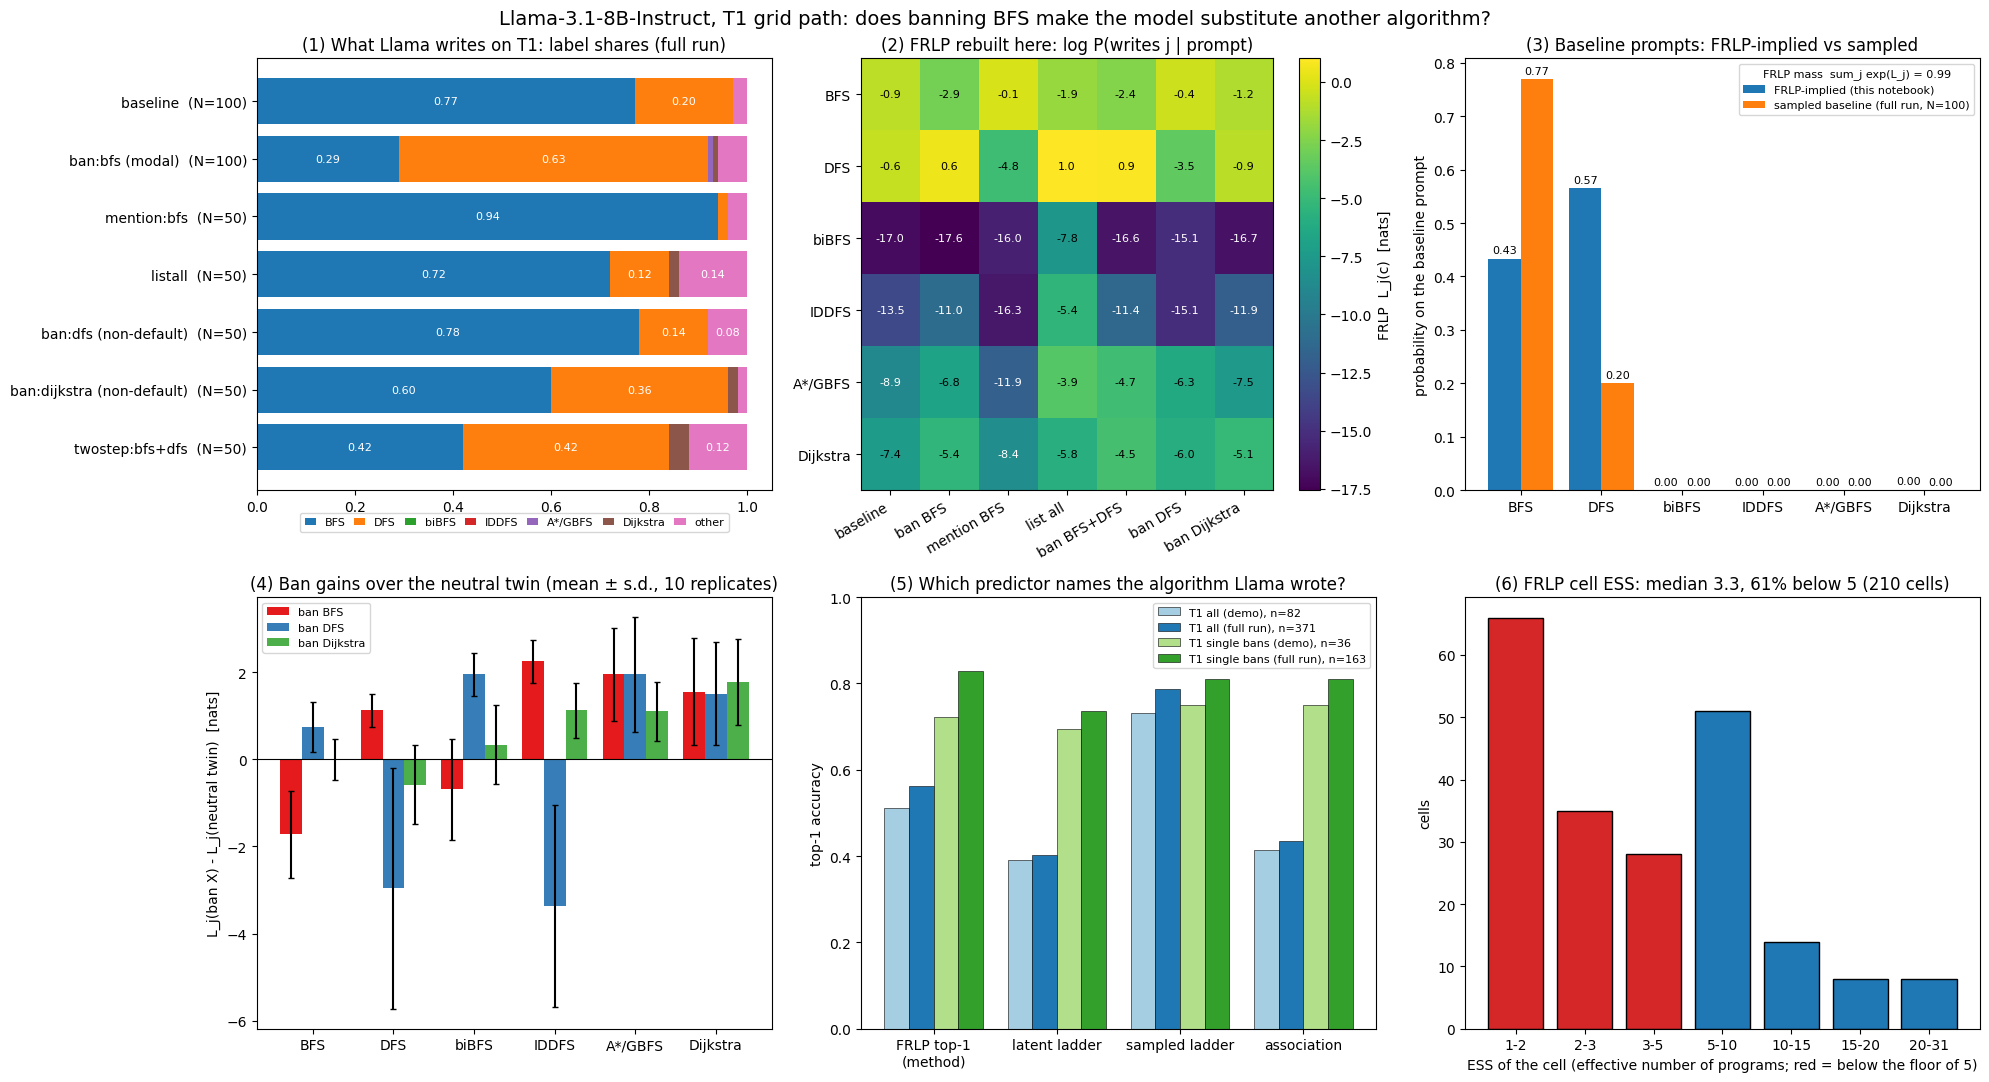

In [20]:
ALG_NAMES = {"bfs": "BFS", "dfs": "DFS", "bibfs": "biBFS", "iddfs": "IDDFS", "astar_gbfs": "A*/GBFS",
             "dijkstra": "Dijkstra", "other": "other"}
algs = td1.algs
x = np.arange(len(algs))
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# (1) what Llama writes: label shares per sampled event, full run
ax = axes[0, 0]
ev_full = _file(RESULTS / "events.json")["t1"]
left = np.zeros(len(ev_full))
for k, lab in enumerate([*algs, "other"]):
    share = np.array([e["attempted_counts"].get(lab, 0) / max(1, sum(e["attempted_counts"].values())) for e in ev_full])
    ax.barh(np.arange(len(ev_full)), share, left=left, color=plt.cm.tab10(k), label=ALG_NAMES[lab])
    for i, (l0, s_) in enumerate(zip(left, share)):
        if s_ >= 0.08:
            ax.text(l0 + s_ / 2, i, f"{s_:.2f}", ha="center", va="center", fontsize=8, color="w")
    left += share
ax.set_yticks(np.arange(len(ev_full)), [f'{e["name"]}  (N={e["N"]})' for e in ev_full])
ax.invert_yaxis()
ax.set_title("(1) What Llama writes on T1: label shares (full run)")
ax.legend(fontsize=8, ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.04), handlelength=1, columnspacing=0.8)

# (2) FRLP cells rebuilt in this notebook, per algorithm and event
ax = axes[0, 1]
Lm = L_event.to_numpy()
im = ax.imshow(Lm, cmap="viridis", aspect="auto")
mid = (np.nanmin(Lm) + np.nanmax(Lm)) / 2
for i in range(Lm.shape[0]):
    for j in range(Lm.shape[1]):
        ax.text(j, i, f"{Lm[i, j]:.1f}", ha="center", va="center", fontsize=8, color="w" if Lm[i, j] < mid else "k")
ax.set_xticks(np.arange(Lm.shape[1]), L_event.columns, rotation=30, ha="right")
ax.set_yticks(x, [ALG_NAMES[a] for a in algs])
fig.colorbar(im, ax=ax, label="FRLP  L_j(c)  [nats]")
ax.set_title("(2) FRLP rebuilt here: log P(writes j | prompt)")

# (3) FRLP-implied vs sampled distribution on the 5 baseline prompts (FRLP gate, part a)
ax = axes[0, 2]
sig = [float(np.nansum(np.exp(v1.a(f"baseline:s{s}", algs)))) for s in range(5)]
implied = {j: float(np.mean([np.exp(v1.a(f"baseline:s{s}", [j])[0]) / sig[s] for s in range(5)])) for j in algs}
col = _file(RESULTS / "collapse.json")["t1"]
sampled = {j: col["attempted_counts"].get(j, 0) / col["attempted"] for j in algs}
ax.bar(x - 0.2, [implied[j] for j in algs], 0.4, label="FRLP-implied (this notebook)")
ax.bar(x + 0.2, [sampled[j] for j in algs], 0.4, label=f'sampled baseline (full run, N={col["attempted"]})')
for i, j in enumerate(algs):
    ax.text(i - 0.2, implied[j] + 0.01, f"{implied[j]:.2f}", ha="center", fontsize=8)
    ax.text(i + 0.2, sampled[j] + 0.01, f"{sampled[j]:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [ALG_NAMES[a] for a in algs])
ax.set_ylabel("probability on the baseline prompt")
ax.set_title("(3) Baseline prompts: FRLP-implied vs sampled")
ax.legend(fontsize=8, title=f"FRLP mass  sum_j exp(L_j) = {np.mean(sig):.2f}", title_fontsize=8)

# (4) what a ban does: gain of each algorithm over the length-matched neutral twin
ax = axes[1, 0]
for b, X in enumerate(["bfs", "dfs", "dijkstra"]):
    G = np.array([v1.G(X, w, h, algs, "neutral") for w in TEMPLATES for h in HALVES])  # [10 replicates, J]
    ax.bar(x + (b - 1) * 0.27, np.nanmean(G, axis=0), 0.27, yerr=np.nanstd(G, axis=0), capsize=2,
           color=plt.cm.Set1(b), label=f"ban {ALG_NAMES[X]}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, [ALG_NAMES[a] for a in algs])
ax.set_ylabel("L_j(ban X) - L_j(neutral twin)  [nats]")
ax.set_title("(4) Ban gains over the neutral twin (mean ± s.d., 10 replicates)")
ax.legend(fontsize=8)

# (5) per-sample top-1 accuracy of the four predictors
ax = axes[1, 1]
bars = {"T1 all (demo)": ps["ALL"], "T1 all (full run)": t1_total(full),
        "T1 single bans (demo)": ps["SINGLE_BANS"], "T1 single bans (full run)": t1_total(full, single_bans=True)}
xb = np.arange(len(ACC))
for b, (name, d) in enumerate(bars.items()):
    ax.bar(xb + (b - 1.5) * 0.2, [d[a] for a in ACC], 0.2, label=f'{name}, n={d["n"]}',
           color=plt.cm.Paired(b), edgecolor="k", lw=0.4)
ax.set_xticks(xb, ["FRLP top-1\n(method)", "latent ladder", "sampled ladder", "association"])
ax.set_ylim(0, 1)
ax.set_ylabel("top-1 accuracy")
ax.set_title("(5) Which predictor names the algorithm Llama wrote?")
ax.legend(fontsize=8)

# (6) effective sample size of the FRLP cells used here
ax = axes[1, 2]
ess = np.concatenate([[v1.c.ESSa[:, td1.cidx[c]] for c in cs] for cs in EVENTS.values()]).ravel()
ess = ess[~np.isnan(ess)]
edges = [1, 2, 3, 5, 10, 15, 20, 31]
counts = np.histogram(ess, bins=edges)[0]
ax.bar(np.arange(len(counts)), counts, color=["tab:red" if lo < ESS_FLOOR else "tab:blue" for lo in edges[:-1]],
       edgecolor="k")
ax.set_xticks(np.arange(len(counts)), [f"{lo}-{hi}" for lo, hi in zip(edges[:-1], edges[1:])])
ax.set_xlabel("ESS of the cell (effective number of programs; red = below the floor of 5)")
ax.set_ylabel("cells")
ax.set_title(f"(6) FRLP cell ESS: median {np.median(ess):.1f}, {np.mean(ess < ESS_FLOOR):.0%} below 5 "
             f"({len(ess)} cells)")

fig.suptitle("Llama-3.1-8B-Instruct, T1 grid path: does banning BFS make the model substitute another algorithm?",
             fontsize=14)
fig.tight_layout()
plt.show()

## What to take away

* **On T1 a ban substitutes a specific runner-up.** Banning BFS moves most samples to DFS (panel 1). FRLP shows the same
  shift (panel 4): under the ban, BFS loses about 1.7 nats against the neutral twin and DFS gains about 1 nat. On T2
  (not in this demo) the Dijkstra ban is followed only partly: Dijkstra 43, other 37 and BF/SPFA 18 of 100.
* **Naming an absent algorithm in a ban can raise it** (panel 4). Llama never writes Dijkstra on the T1 baseline, yet
  banning it *raises* its FRLP by about 1.8 nats. In the full run this holds in 5 of 6 such cases. The mention twin
  primes the named algorithm by 6.7–14.4 nats, and the ban's veto (−4.9 to −10.1) cancels only part of that.
* **FRLP is a noisy instrument here.** On the baseline prompts it puts 0.57 on DFS where sampling gives 0.20 (panel 3;
  part (a) of the gate fails). Most cells rest on fewer than 5 effective programs (panel 6). Over all T1 events, the
  plain sampled ladder predicts single samples much better than FRLP (0.79 vs 0.56 in the full run), mostly because
  FRLP picks DFS on BFS-dominated prompts. On single bans the two are close (panel 5).
* Every number is descriptive (two tasks, one model). The C1 share test is "not resolved at this N" under the neutral
  reference and "X-specific but unaimed" under the mention reference (`data["files"]["results/c1.json"]["branches"]`),
  so it is not robust.

**Scaling back up.** `N_EXAMPLES = 100` processes every curated example. The full run, `python method.py outputs` in
the experiment folder, processes all 450 T1 + 450 T2 sampled programs, 880 forced programs and 220 free-form answers
against the complete score matrices (39,768 HF program scores). Doing that here would need `TASKS = ("t1", "t2")` and
the full `frlp/parts/` and `data/` files.